# Cell 1: Import libraries and verify dependencies

In [1]:



import os
import cv2
import numpy as np
import pandas as pd
import pywt
import pickle
import joblib

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("All imports successful.")
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyWavelets:", pywt.__version__)


All imports successful.
OpenCV: 4.13.0
NumPy: 2.3.5
Pandas: 2.3.3
PyWavelets: 1.8.0


# Cell 2: Configure paths and inspect dataset

In [2]:

# Cell 2: Configure paths and inspect dataset

INPUT_DIR = Path(
    r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Tumor_ROI_Morphology"
)

OUTPUT_DIR = Path(
    r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input folder exists:", INPUT_DIR.exists())
print("Output folder:", OUTPUT_DIR)
print("Output folder exists:", OUTPUT_DIR.exists())

if not INPUT_DIR.exists():
    print("\nERROR: Input folder not found. Check the path.")
else:
    print("\nTop-level folders and image counts:")

    image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

    for folder in sorted(INPUT_DIR.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for p in folder.rglob("*")
                if p.is_file() and p.suffix.lower() in image_extensions
            )
            print(f"{folder.name}: {count} images")

    total_images = sum(
        1 for p in INPUT_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    print(f"\nTotal images found: {total_images}")


Input folder exists: True
Output folder: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT
Output folder exists: True

Top-level folders and image counts:
test: 830 images
train: 3883 images

Total images found: 4713


# Cell 3: Inspect class distribution and image properties

In [3]:

# Cell 3: Inspect class distribution and image properties

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

for split in ["train", "test"]:
    split_dir = INPUT_DIR / split

    print(f"\n{'=' * 55}")
    print(f"Split: {split}")

    if not split_dir.exists():
        print("Split folder not found!")
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        images = [
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        print(f"\nClass: {class_dir.name}")
        print(f"Image count: {len(images)}")

        if images:
            sample_path = images[0]
            image = cv2.imread(str(sample_path), cv2.IMREAD_UNCHANGED)

            if image is not None:
                print(f"Sample file: {sample_path.name}")
                print(f"Image shape: {image.shape}")
                print(f"Data type: {image.dtype}")
                print(f"Pixel range: {image.min()} to {image.max()}")
            else:
                print("WARNING: Could not read sample image.")



Split: train

Class: glioma
Image count: 1108
Sample file: brisc2025_train_00001_gl_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 186

Class: meningioma
Image count: 1320
Sample file: brisc2025_train_01148_me_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 197

Class: pituitary
Image count: 1455
Sample file: brisc2025_train_02477_pi_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 219

Split: test

Class: glioma
Image count: 234
Sample file: brisc2025_test_00001_gl_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 115

Class: meningioma
Image count: 301
Sample file: brisc2025_test_00255_me_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 223

Class: pituitary
Image count: 295
Sample file: brisc2025_test_00561_pi_ax_t1.jpg
Image shape: (256, 256)
Data type: uint8
Pixel range: 0 to 200


# Cell 4: Visualize representative images from each class

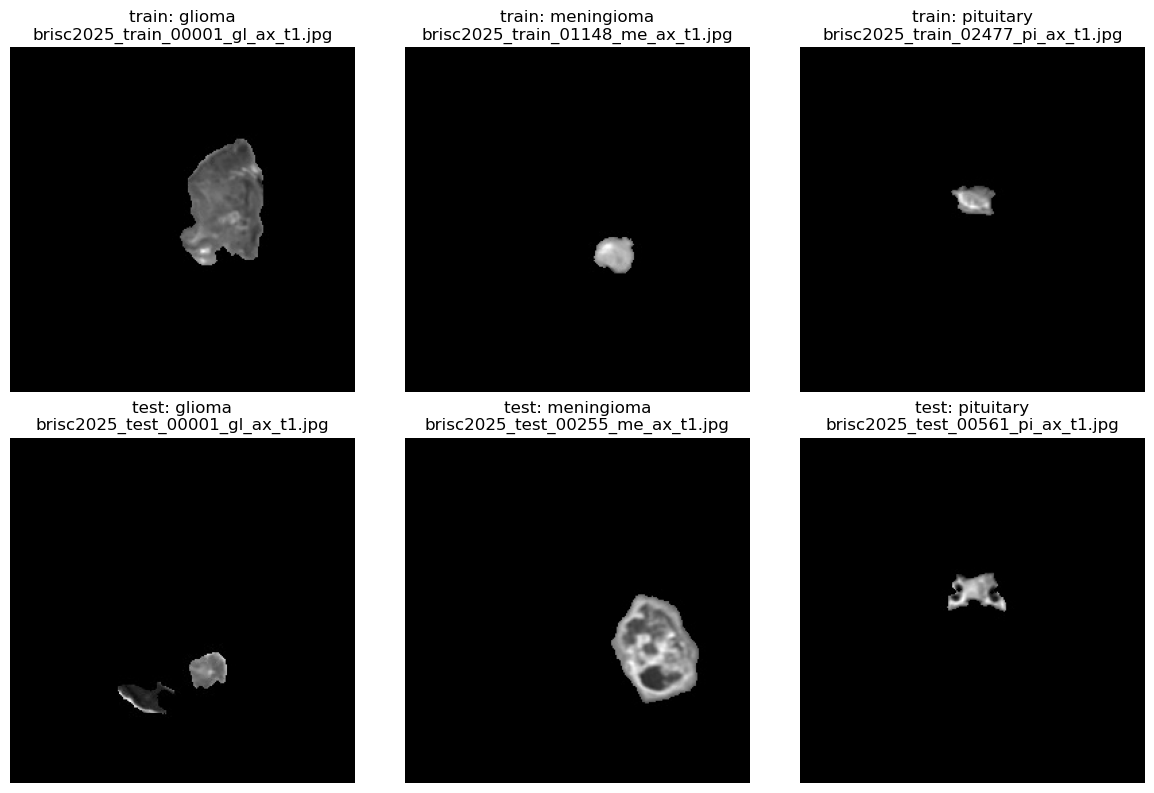

In [4]:

# Cell 4: Visualize representative images from each class

import matplotlib.pyplot as plt

classes = ["glioma", "meningioma", "pituitary"]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, split in enumerate(["train", "test"]):
    for col, class_name in enumerate(classes):
        class_dir = INPUT_DIR / split / class_name

        image_paths = sorted([
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        if not image_paths:
            axes[row, col].set_title(f"{split}: {class_name} (empty)")
            axes[row, col].axis("off")
            continue

        image_path = image_paths[0]
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(
            f"{split}: {class_name}\n{image_path.name}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


# Cell 5: Test bounding-box ROI cropping

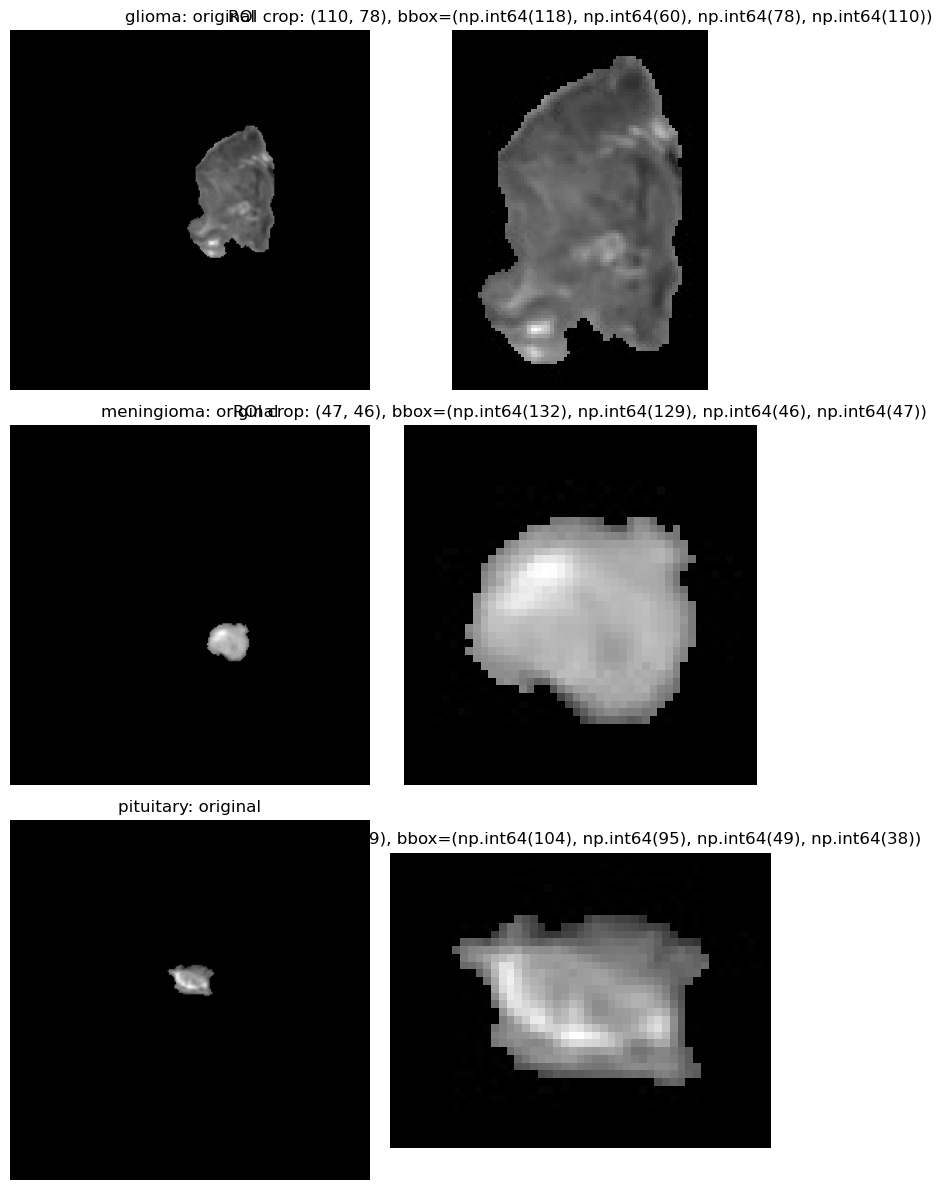

In [5]:

# Cell 5: Test bounding-box ROI cropping

def crop_tumor_roi(image, threshold=5, margin=8):
    """
    Crop the non-black region with a margin.
    Returns the cropped image and its bounding box (x, y, w, h).
    """
    mask = image > threshold

    if not np.any(mask):
        return image.copy(), (0, 0, image.shape[1], image.shape[0])

    ys, xs = np.where(mask)

    x1, x2 = xs.min(), xs.max() + 1
    y1, y2 = ys.min(), ys.max() + 1

    x1 = max(0, x1 - margin)
    y1 = max(0, y1 - margin)
    x2 = min(image.shape[1], x2 + margin)
    y2 = min(image.shape[0], y2 + margin)

    cropped = image[y1:y2, x1:x2]

    return cropped, (x1, y1, x2 - x1, y2 - y1)


fig, axes = plt.subplots(3, 2, figsize=(8, 12))

for row, class_name in enumerate(classes):
    image_path = next(
        p for p in sorted((INPUT_DIR / "train" / class_name).rglob("*"))
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    cropped, bbox = crop_tumor_roi(image)

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"{class_name}: original")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cropped, cmap="gray")
    axes[row, 1].set_title(f"ROI crop: {cropped.shape}, bbox={bbox}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


# Cell 6: Test SWT feature extraction on one image per class

In [6]:

# Cell 6: Test SWT feature extraction on one image per class

SWT_WAVELET = "db2"
SWT_LEVEL = 2
SWT_IMAGE_SIZE = (128, 128)

def extract_swt_features(image):
    """
    Crop the non-black ROI, resize it, and extract
    statistical features from two-level SWT subbands.
    """
    cropped, bbox = crop_tumor_roi(image, threshold=5, margin=8)

    resized = cv2.resize(
        cropped,
        SWT_IMAGE_SIZE,
        interpolation=cv2.INTER_AREA
    )

    normalized = resized.astype(np.float32) / 255.0

    # SWT requires image dimensions divisible by 2**SWT_LEVEL.
    coeffs = pywt.swt2(
        normalized,
        wavelet=SWT_WAVELET,
        level=SWT_LEVEL,
        axes=(0, 1)
    )

    features = {}

    for level_idx, (approx, (horizontal, vertical, diagonal)) in enumerate(
        coeffs, start=1
    ):
        subbands = {
            "LL": approx,
            "LH": horizontal,
            "HL": vertical,
            "HH": diagonal
        }

        for band_name, band in subbands.items():
            prefix = f"L{level_idx}_{band_name}"

            features[f"{prefix}_mean"] = float(np.mean(band))
            features[f"{prefix}_std"] = float(np.std(band))
            features[f"{prefix}_energy"] = float(np.mean(band ** 2))
            features[f"{prefix}_entropy"] = float(
                -np.sum(
                    (hist := np.histogram(
                        band, bins=64, density=False
                    )[0].astype(np.float64)) /
                    max(hist.sum(), 1) *
                    np.log2(
                        np.maximum(
                            hist / max(hist.sum(), 1), 1e-12
                        )
                    )
                )
            )

    return features


for class_name in classes:
    image_path = next(
        p for p in sorted((INPUT_DIR / "train" / class_name).rglob("*"))
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    features = extract_swt_features(image)

    print(f"\nClass: {class_name}")
    print("Sample:", image_path.name)
    print("Feature count:", len(features))
    print("All values finite:", np.isfinite(list(features.values())).all())
    print("First 8 features:")

    for name, value in list(features.items())[:8]:
        print(f"  {name}: {value:.6f}")



Class: glioma
Sample: brisc2025_train_00001_gl_ax_t1.jpg
Feature count: 32
All values finite: True
First 8 features:
  L1_LL_mean: 0.561388
  L1_LL_std: 0.574616
  L1_LL_energy: 0.645340
  L1_LL_entropy: 3.880592
  L1_LH_mean: 0.000000
  L1_LH_std: 0.070719
  L1_LH_energy: 0.005001
  L1_LH_entropy: 3.307615

Class: meningioma
Sample: brisc2025_train_01148_me_ax_t1.jpg
Feature count: 32
All values finite: True
First 8 features:
  L1_LL_mean: 0.601871
  L1_LL_std: 0.939601
  L1_LL_energy: 1.245098
  L1_LL_entropy: 3.030451
  L1_LH_mean: 0.000000
  L1_LH_std: 0.056467
  L1_LH_energy: 0.003189
  L1_LH_entropy: 2.037014

Class: pituitary
Sample: brisc2025_train_02477_pi_ax_t1.jpg
Feature count: 32
All values finite: True
First 8 features:
  L1_LL_mean: 0.539895
  L1_LL_std: 0.891623
  L1_LL_energy: 1.086478
  L1_LL_entropy: 2.917831
  L1_LH_mean: 0.000000
  L1_LH_std: 0.053906
  L1_LH_energy: 0.002906
  L1_LH_entropy: 2.418640


# Cell 7: Visualize the four SWT subbands for one tumor per class

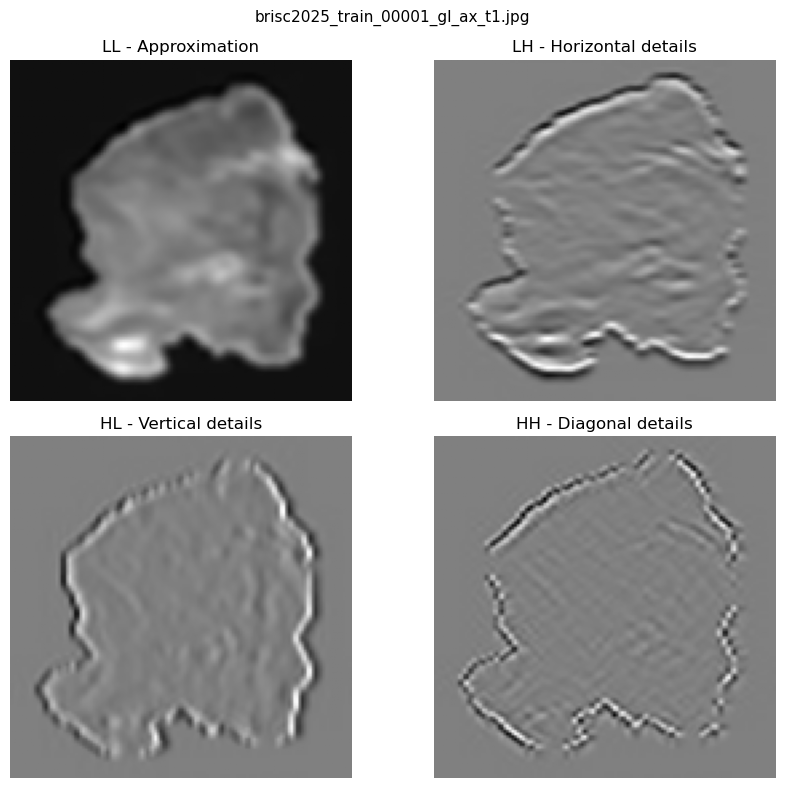

In [9]:

# Enter the path of any segmented tumor image
IMAGE_PATH = r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Tumor_ROI_Morphology\train\glioma\brisc2025_train_00001_gl_ax_t1.jpg"

def visualize_swt(image_path):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError("Could not read the image.")

    # Crop the non-black ROI and resize
    cropped, bbox = crop_tumor_roi(
        image, threshold=5, margin=8
    )

    resized = cv2.resize(
        cropped,
        SWT_IMAGE_SIZE,
        interpolation=cv2.INTER_AREA
    ).astype(np.float32) / 255.0

    # Two-level Stationary Wavelet Transform
    coeffs = pywt.swt2(
        resized,
        wavelet=SWT_WAVELET,
        level=SWT_LEVEL,
        axes=(0, 1)
    )

    # Four subbands from the first decomposition level
    approx, (horizontal, vertical, diagonal) = coeffs[0]

    subbands = [
        (approx, "LL - Approximation"),
        (horizontal, "LH - Horizontal details"),
        (vertical, "HL - Vertical details"),
        (diagonal, "HH - Diagonal details")
    ]

    fig, axes = plt.subplots(2, 2, figsize=(9, 8))

    for ax, (band, title) in zip(axes.flat, subbands):
        if title.startswith("LL"):
            ax.imshow(band, cmap="gray")
        else:
            limit = max(float(np.max(np.abs(band))), 1e-8)
            ax.imshow(
                band,
                cmap="gray",
                vmin=-limit,
                vmax=limit
            )

        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(image_path.name, fontsize=11)
    plt.tight_layout()
    plt.show()

# Run visualization
visualize_swt(IMAGE_PATH)


# Cell 8: Extract and save SWT features for train and test

In [10]:

# Cell 8: Extract and save SWT features for train and test

all_features = {"train": [], "test": []}
processing_log = []

for split in ["train", "test"]:
    print(f"\nProcessing {split} split...")

    for class_name in classes:
        class_dir = INPUT_DIR / split / class_name

        image_paths = sorted(
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        for image_path in tqdm(image_paths, desc=f"{split}/{class_name}"):
            try:
                image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

                if image is None:
                    raise ValueError("Unable to read image")

                features = extract_swt_features(image)

                all_features[split].append({
                    "filename": image_path.name,
                    "split": split,
                    "label": class_name,
                    **features
                })

                processing_log.append({
                    "filename": image_path.name,
                    "split": split,
                    "label": class_name,
                    "status": "success",
                    "error": ""
                })

            except Exception as exc:
                processing_log.append({
                    "filename": image_path.name,
                    "split": split,
                    "label": class_name,
                    "status": "failed",
                    "error": str(exc)
                })

    df = pd.DataFrame(all_features[split])
    output_file = OUTPUT_DIR / f"swt_{split}.csv"
    df.to_csv(output_file, index=False)

    print(f"Saved: {output_file}")
    print(f"Successful images: {len(df)}")

log_df = pd.DataFrame(processing_log)
log_df.to_csv(OUTPUT_DIR / "processing_log.csv", index=False)

print("\nProcessing summary:")
print(log_df.groupby(["split", "status"]).size())
print("\nOutput directory:", OUTPUT_DIR)



Processing train split...


train/glioma:   0%|          | 0/1108 [00:00<?, ?it/s]

train/meningioma:   0%|          | 0/1320 [00:00<?, ?it/s]

train/pituitary:   0%|          | 0/1455 [00:00<?, ?it/s]

Saved: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\swt_train.csv
Successful images: 3883

Processing test split...


test/glioma:   0%|          | 0/234 [00:00<?, ?it/s]

test/meningioma:   0%|          | 0/301 [00:00<?, ?it/s]

test/pituitary:   0%|          | 0/295 [00:00<?, ?it/s]

Saved: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\swt_test.csv
Successful images: 830

Processing summary:
split  status 
test   success     830
train  success    3883
dtype: int64

Output directory: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT


# Cell 9: Validate extracted SWT features

In [11]:

# Cell 9: Validate extracted SWT features

train_df = pd.read_csv(OUTPUT_DIR / "swt_train.csv")
test_df = pd.read_csv(OUTPUT_DIR / "swt_test.csv")

metadata_cols = ["filename", "split", "label"]
feature_cols = [
    col for col in train_df.columns
    if col not in metadata_cols
]

print("TRAIN")
print("Shape:", train_df.shape)
print("Class distribution:")
print(train_df["label"].value_counts())
print("Missing feature values:", train_df[feature_cols].isna().sum().sum())
print("Infinite feature values:",
      np.isinf(train_df[feature_cols].to_numpy()).sum())
print("Duplicate filenames:", train_df["filename"].duplicated().sum())

print("\nTEST")
print("Shape:", test_df.shape)
print("Class distribution:")
print(test_df["label"].value_counts())
print("Missing feature values:", test_df[feature_cols].isna().sum().sum())
print("Infinite feature values:",
      np.isinf(test_df[feature_cols].to_numpy()).sum())
print("Duplicate filenames:", test_df["filename"].duplicated().sum())

print("\nFeature count:", len(feature_cols))
print("Train/test feature columns match:",
      feature_cols == [
          col for col in test_df.columns
          if col not in metadata_cols
      ])


TRAIN
Shape: (3883, 35)
Class distribution:
label
pituitary     1455
meningioma    1320
glioma        1108
Name: count, dtype: int64
Missing feature values: 0
Infinite feature values: 0
Duplicate filenames: 0

TEST
Shape: (830, 35)
Class distribution:
label
meningioma    301
pituitary     295
glioma        234
Name: count, dtype: int64
Missing feature values: 0
Infinite feature values: 0
Duplicate filenames: 0

Feature count: 32
Train/test feature columns match: True


# Cell 10: Scale SWT features and apply PCA

In [16]:
import json

metadata = {
    "n_components": PCA_COMPONENTS,
    "explained_variance_ratio_sum": float(
        swt_pca.explained_variance_ratio_.sum()
    ),
    "original_feature_count": len(feature_cols)
}

with open(OUTPUT_DIR / "swt_metadata.pkl.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully.")
print(f"PCA components: {PCA_COMPONENTS}")
print(f"Variance retained: {metadata['explained_variance_ratio_sum']:.4%}")

Metadata saved successfully.
PCA components: 28
Variance retained: 99.9949%


In [20]:

# Cell 10: Scale SWT features and overwrite PCA outputs

PCA_COMPONENTS = 30  # Change to 30 for the next experiment

train_df = pd.read_csv(OUTPUT_DIR / "swt_train.csv")
test_df = pd.read_csv(OUTPUT_DIR / "swt_test.csv")

metadata_cols = ["filename", "split", "label"]
feature_cols = [c for c in train_df.columns if c not in metadata_cols]

assert feature_cols == [
    c for c in test_df.columns if c not in metadata_cols
]

X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
X_test = test_df[feature_cols].to_numpy(dtype=np.float64)

# Fit scaler on training data only
swt_scaler = StandardScaler()
X_train_scaled = swt_scaler.fit_transform(X_train)
X_test_scaled = swt_scaler.transform(X_test)

# Fit PCA
swt_pca = PCA(
    n_components=PCA_COMPONENTS,
    svd_solver="full"
)

X_train_pca = swt_pca.fit_transform(X_train_scaled)
X_test_pca = swt_pca.transform(X_test_scaled)

pca_columns = [
    f"SWT_PCA_{i+1:02d}" for i in range(PCA_COMPONENTS)
]

pca_train_df = pd.DataFrame(X_train_pca, columns=pca_columns)
pca_test_df = pd.DataFrame(X_test_pca, columns=pca_columns)

# Restore metadata
for df, source_df, split_name in [
    (pca_train_df, train_df, "train"),
    (pca_test_df, test_df, "test")
]:
    df.insert(0, "label", source_df["label"].to_numpy())
    df.insert(0, "split", split_name)
    df.insert(0, "filename", source_df["filename"].to_numpy())

# Overwrite existing files
pca_train_df.to_csv(OUTPUT_DIR / "pca_swt_train.csv", index=False)
pca_test_df.to_csv(OUTPUT_DIR / "pca_swt_test.csv", index=False)

joblib.dump(swt_scaler, OUTPUT_DIR / "swt_scaler.pkl")
joblib.dump(swt_pca, OUTPUT_DIR / "swt_pca.pkl")
joblib.dump(feature_cols, OUTPUT_DIR / "swt_feature_columns.pkl")
joblib.dump(pca_columns, OUTPUT_DIR / "swt_pca_columns.pkl")

metadata = {
    "n_components": PCA_COMPONENTS,
    "explained_variance_ratio_sum": float(
        swt_pca.explained_variance_ratio_.sum()
    ),
    "original_feature_count": len(feature_cols)
}

with open(OUTPUT_DIR / "swt_metadata.pkl.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("PCA outputs overwritten successfully.")
print("Components:", PCA_COMPONENTS)
print(f"Variance retained: {metadata['explained_variance_ratio_sum']:.4%}")
print("Training shape:", pca_train_df.shape)
print("Testing shape:", pca_test_df.shape)
print("Output directory:", OUTPUT_DIR)


PCA outputs overwritten successfully.
Components: 30
Variance retained: 100.0000%
Training shape: (3883, 33)
Testing shape: (830, 33)
Output directory: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT


# Cell 11: Save PCA features and preprocessing artifacts

In [21]:

# Cell 11: Save PCA features and preprocessing artifacts

# Create PCA feature tables while preserving image metadata
pca_columns = [
    f"SWT_PCA_{i+1:02d}" for i in range(swt_pca.n_components_)
]

pca_train_df = train_df[metadata_cols].copy()
pca_test_df = test_df[metadata_cols].copy()

pca_train_df[pca_columns] = X_train_pca
pca_test_df[pca_columns] = X_test_pca

# Save transformed features
pca_train_path = OUTPUT_DIR / "pca_swt_train.csv"
pca_test_path = OUTPUT_DIR / "pca_swt_test.csv"

pca_train_df.to_csv(pca_train_path, index=False)
pca_test_df.to_csv(pca_test_path, index=False)

# Save fitted preprocessing objects
joblib.dump(swt_scaler, OUTPUT_DIR / "swt_scaler.pkl")
joblib.dump(swt_pca, OUTPUT_DIR / "swt_pca.pkl")

# Save feature-column definitions
joblib.dump(feature_cols, OUTPUT_DIR / "swt_feature_columns.pkl")
joblib.dump(pca_columns, OUTPUT_DIR / "swt_pca_columns.pkl")

# Save metadata describing the configuration
swt_metadata = {
    "wavelet": SWT_WAVELET,
    "swt_level": SWT_LEVEL,
    "image_size": SWT_IMAGE_SIZE,
    "roi_threshold": 5,
    "roi_margin": 8,
    "original_feature_count": len(feature_cols),
    "pca_component_count": swt_pca.n_components_,
    "variance_retained": float(
        swt_pca.explained_variance_ratio_.sum()
    ),
    "classes": classes
}

joblib.dump(swt_metadata, OUTPUT_DIR / "swt_metadata.pkl")

print("Saved PCA train:", pca_train_path)
print("Saved PCA test:", pca_test_path)
print("Saved scaler, PCA model, feature columns, and metadata.")

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size / 1024:.1f} KB")


Saved PCA train: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\pca_swt_train.csv
Saved PCA test: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\pca_swt_test.csv
Saved scaler, PCA model, feature columns, and metadata.

Output files:
pca_swt_test.csv: 533.6 KB
pca_swt_train.csv: 2504.9 KB
processing_log.csv: 276.8 KB
swt_feature_columns.pkl: 0.5 KB
swt_metadata.pkl: 0.2 KB
swt_metadata.pkl.json: 0.1 KB
swt_pca.pkl: 9.4 KB
swt_pca_columns.pkl: 0.4 KB
swt_scaler.pkl: 1.4 KB
swt_test.csv: 570.2 KB
swt_train.csv: 2675.1 KB


# Cell 12: Verify saved artifacts and transformation consistency

In [22]:

# Cell 12: Verify saved artifacts and transformation consistency

# Reload saved artifacts
loaded_scaler = joblib.load(OUTPUT_DIR / "swt_scaler.pkl")
loaded_pca = joblib.load(OUTPUT_DIR / "swt_pca.pkl")
loaded_feature_cols = joblib.load(
    OUTPUT_DIR / "swt_feature_columns.pkl"
)

# Reload raw test features
raw_test_df = pd.read_csv(OUTPUT_DIR / "swt_test.csv")
saved_pca_test_df = pd.read_csv(
    OUTPUT_DIR / "pca_swt_test.csv"
)

X_test_raw = raw_test_df[loaded_feature_cols].to_numpy(dtype=np.float64)

# Reproduce PCA test features
X_test_reproduced = loaded_pca.transform(
    loaded_scaler.transform(X_test_raw)
)

saved_pca_cols = joblib.load(OUTPUT_DIR / "swt_pca_columns.pkl")
X_test_saved = saved_pca_test_df[saved_pca_cols].to_numpy()

print("Scaler loaded:", isinstance(loaded_scaler, StandardScaler))
print("PCA loaded:", isinstance(loaded_pca, PCA))
print("Raw test shape:", X_test_raw.shape)
print("Saved PCA test shape:", X_test_saved.shape)

print(
    "Maximum absolute difference:",
    np.max(np.abs(X_test_reproduced - X_test_saved))
)

print(
    "Transformation matches:",
    np.allclose(X_test_reproduced, X_test_saved, atol=1e-8)
)

print("\nSaved files verified.")


Scaler loaded: True
PCA loaded: True
Raw test shape: (830, 32)
Saved PCA test shape: (830, 30)
Maximum absolute difference: 3.552713678800501e-15
Transformation matches: True

Saved files verified.
